# 017 — MLP com ponderação mais suave

## Objetivo e protocolo

Parte do MLP 015: arquitetura 64 → 32, ReLU, Adam com taxa 0.0001, `weight_decay=0`, `batch_size=128` e até 100 épocas. Compara `CrossEntropyLoss` ponderada por 1/frequência (controlo 015) com 1/√frequência (nova variante, pesos normalizados para média 1). Ambas as versões começam com rede, otimizador, embaralhamento e sementes reiniciados.

A divisão estratificada fixa 80/20 e a validação interna estratificada de 15% são as mesmas do 015, ambas com semente 42. A época de cada versão é escolhida apenas pela Macro F1 interna. O pré-processador e os pesos são reajustados apenas nos dados de treino de cada fase. A variante suave é avaliada nos 20% fixos e exportada após novo treino nas 10.962 linhas rotuladas.

Referência 015: Macro F1 fixa **0.4224**, Kaggle **0.44**.

,versão,best_epoch,best_internal_macro_f1,training_seconds
0,inverso,93,0.4792,22.5
1,inverso_raiz,75,0.4927,21.4


,modelo,macro_f1,accuracy,diferença vs 015
0,Controlo 1/frequência,0.4224,0.4191,+0.0000
1,Variante 1/√frequência,0.4351,0.4300,+0.0127


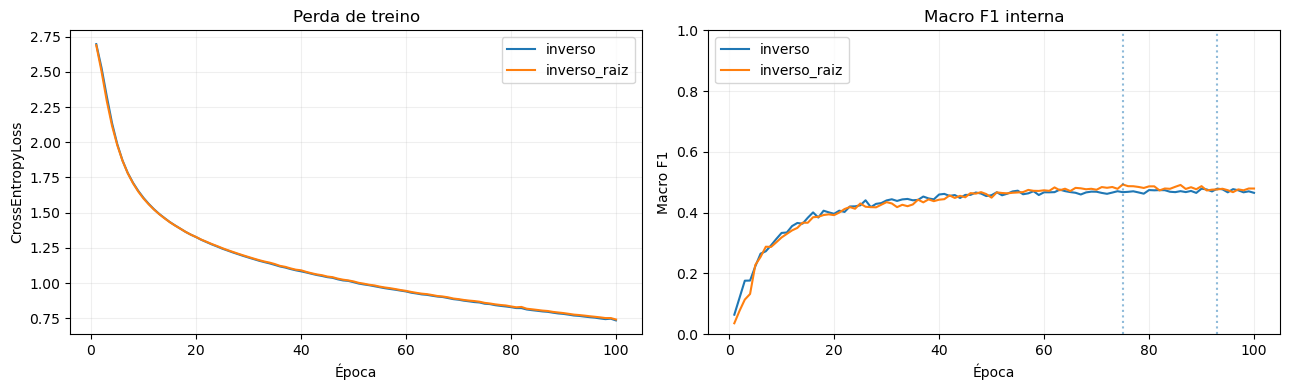

,classe,escalão,F1,recall,support
0,0,15–17 anos,0.7089,0.6829,41
1,1,18–19 anos,0.4595,0.5000,34
2,2,20–24 anos,0.4935,0.4750,80
3,3,25–29 anos,0.3399,0.3467,75
4,4,30–34 anos,0.2944,0.3222,90
5,5,35–39 anos,0.3774,0.3876,129
6,6,40–44 anos,0.3558,0.3372,172
7,7,45–49 anos,0.3588,0.3526,173
8,8,50–54 anos,0.6022,0.6022,181
9,9,55–59 anos,0.5964,0.5714,203


,classe,escalão,F1 015,F1 suave,Δ F1,recall 015,recall suave,Δ recall
0,1,18–19 anos,0.473118,0.459459,-0.0137,0.647059,0.500000,-0.1471
1,6,40–44 anos,0.346269,0.355828,+0.0096,0.337209,0.337209,+0.0000
2,13,75–79 anos,0.215686,0.272189,+0.0565,0.200000,0.278788,+0.0788


Exploratória face à referência 015: False; CSV: submissions/submission_017_mlp_ponderacao_suave.csv


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

repo_root = next(p for p in [Path.cwd(), *Path.cwd().resolve().parents]
                 if (p / "src" / "experiments_016_018.py").is_file())
sys.path.insert(0, str(repo_root))
from src.experiments_016_018 import run_017

output = run_017()
result, histories = output["result"], output["histories"]
selection = pd.DataFrame([
    {"versão": label, **values}
    for label, values in result["selections"].items()
])
display(selection.style.format({"best_internal_macro_f1": "{:.4f}", "training_seconds": "{:.1f}"}))
metrics = pd.DataFrame([
    {"modelo": "Controlo 1/frequência", **result["control_metrics"]},
    {"modelo": "Variante 1/√frequência", **result["soft_metrics"]},
])[["modelo", "macro_f1", "accuracy"]]
metrics["diferença vs 015"] = metrics.macro_f1 - 0.4224
display(metrics.style.format({"macro_f1": "{:.4f}", "accuracy": "{:.4f}", "diferença vs 015": "{:+.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, history in histories.items():
    axes[0].plot(history["epoch"], history["train_loss"], label=label)
    axes[1].plot(history["epoch"], history["validation_macro_f1"], label=label)
    best_epoch = result["selections"][label]["best_epoch"]
    axes[1].axvline(best_epoch, linestyle=":", alpha=.5)
axes[0].set(title="Perda de treino", xlabel="Época", ylabel="CrossEntropyLoss")
axes[1].set(title="Macro F1 interna", xlabel="Época", ylabel="Macro F1", ylim=(0, 1))
for axis in axes:
    axis.grid(alpha=.2)
    axis.legend()
plt.tight_layout()
plt.show()

class_table = pd.DataFrame(result["soft_metrics"]["per_class"])
display(class_table.style.format({"F1": "{:.4f}", "recall": "{:.4f}"}).apply(
    lambda row: ["font-weight: bold" if row.classe in [1, 6, 13] else "" for _ in row], axis=1
))
control = {row["classe"]: row for row in result["control_metrics"]["per_class"]}
key_delta = pd.DataFrame([
    {"classe": row["classe"], "escalão": row["escalão"],
     "F1 015": control[row["classe"]]["F1"], "F1 suave": row["F1"],
     "Δ F1": row["F1"] - control[row["classe"]]["F1"],
     "recall 015": control[row["classe"]]["recall"], "recall suave": row["recall"],
     "Δ recall": row["recall"] - control[row["classe"]]["recall"]}
    for row in result["soft_metrics"]["key_classes"]
])
display(key_delta.style.format({c: "{:+.4f}" for c in ["Δ F1", "Δ recall"]}))
print(f"Exploratória face à referência 015: {result['exploratory']}; CSV: {result['submission']}")

## Conclusão

- Data: 11/11; pontuação Kaggle: 0.46, o melhor MLP no Kaggle atual (018: 0.44; 016, ensemble: 0.48).
- Macro F1 fixa: 0.4351, mais 0.0127 que o 015 (0.4224); a validação fixa já consultada é apenas comparação de desenvolvimento.
- Melhorias: testar dropout mantendo ponderação suave.
